# LeakAudit - 10 - The signal-free baseline (E0)

**How much of each benchmark can be solved without opening the signal at all?**

- Every record carries metadata: which sensor produced it, when it was recorded, which experimental condition it belongs to. If that metadata alone predicts the label, an acoustic score is not evidence of acoustic discrimination.
- We define the **signal-free baseline (SFB)**: accuracy reachable from metadata alone, using a deliberately weak estimator, scored under a group-independent protocol so the estimator cannot memorise the grouping.
- We propose SFB as a mandatory reporting item alongside the majority-class baseline. This notebook computes it for all three benchmarks and produces the paper's headline table and figure.


In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import src as la
from src import config as cfg, io_utils, features, evaluation, sfb
cfg.apply_mpl_style()
RESULTS = {}
rows = []          # accumulates one row per (dataset, task, predictor)

def record(dataset, task, predictor, kind, acc, base, n, note=""):
    """Record one signal-free baseline.

    ``n`` is mandatory: some predictors are only defined on a subset of the
    records (for instance, D2 file names do not all carry a date), and such
    rows have a different class balance. Without n, a larger 'above baseline'
    on a small easy subset would look like a stronger result than it is.
    """
    rows.append(dict(dataset=dataset, task=task, predictor=predictor,
                     protocol=kind, sfb=acc, baseline=base, n=int(n),
                     above_baseline=(acc - base) if acc == acc else np.nan,
                     note=note))
    flag = "" if acc != acc else ("  <-- exceeds baseline" if acc > base + 0.05 else "")
    print(f"  {dataset:4s} {task:16s} {predictor:20s} {kind:14s} "
          f"n={n:<6d} SFB={acc:.4f}  base={base:.4f}{flag}")

## D1 - AI-Hub

Metadata available per record: sensor id (`sid`), site id, acquisition date,
and two device-derived fields (`lrate`, `llevel`). The spectrum is never
touched in this notebook.

Two protocols are reported for each predictor:

* **in-sample** - the *shortcut ceiling*: what the identifier can reach when
  train and test share it. This is what a naive random split permits. It is a
  ceiling, not a deployment estimate.
* **site-independent** - fitted out-of-fold across sites, i.e. what the
  metadata still carries at a genuinely new site.

In [3]:
X1, X1_max, M1, HZ = io_utils.load_d1()
y5 = M1.cls.to_numpy()
y2 = np.where(np.isin(y5, ["out", "in"]), "leak", "nonleak")
base5, base2 = sfb.majority_baseline(y5), sfb.majority_baseline(y2)

N1 = len(M1)

print("D1 - five-class task")
record("D1", "5-class", "sensor id",  "in-sample",
       sfb.sfb_categorical(M1.sid, y5),  base5, N1)
record("D1", "5-class", "site id",    "in-sample",
       sfb.sfb_categorical(M1.site, y5), base5, N1)
record("D1", "5-class", "sensor id",  "site-indep",
       sfb.sfb_categorical(M1.sid, y5, groups=M1.site),  base5, N1)
record("D1", "5-class", "lrate (device)",  "site-indep",
       sfb.sfb_numeric(M1.lrate, y5, groups=M1.site),  base5, N1)
record("D1", "5-class", "llevel (device)", "site-indep",
       sfb.sfb_numeric(M1.llevel, y5, groups=M1.site), base5, N1)
record("D1", "5-class", "all metadata",    "site-indep",
       sfb.sfb_multi(M1, y5, numeric_cols=["lrate", "llevel"],
                     categorical_cols=["sid", "site"], groups=M1.site), base5, N1)

print("\nD1 - leak vs non-leak task")
record("D1", "leak/non-leak", "sensor id", "in-sample",
       sfb.sfb_categorical(M1.sid, y2), base2, N1)
record("D1", "leak/non-leak", "lrate (device)", "site-indep",
       sfb.sfb_numeric(M1.lrate, y2, groups=M1.site), base2, N1)

D1 - five-class task
  D1   5-class          sensor id            in-sample      n=70384  SFB=1.0000  base=0.3149  <-- exceeds baseline
  D1   5-class          site id              in-sample      n=70384  SFB=0.6550  base=0.3149  <-- exceeds baseline
  D1   5-class          sensor id            site-indep     n=70384  SFB=0.3171  base=0.3149
  D1   5-class          lrate (device)       site-indep     n=70384  SFB=0.5953  base=0.3149  <-- exceeds baseline
  D1   5-class          llevel (device)      site-indep     n=70384  SFB=0.3938  base=0.3149  <-- exceeds baseline
  D1   5-class          all metadata         site-indep     n=70384  SFB=0.5686  base=0.3149  <-- exceeds baseline

D1 - leak vs non-leak task
  D1   leak/non-leak    sensor id            in-sample      n=70384  SFB=1.0000  base=0.5075  <-- exceeds baseline
  D1   leak/non-leak    lrate (device)       site-indep     n=70384  SFB=0.8074  base=0.5075  <-- exceeds baseline


### Reading the D1 result

Sensor identity reaches a perfect in-sample score because every sensor is
single-class; that is precisely why a naive random split is uninformative.
Under a site-independent protocol the same identifier collapses to the
majority-class level, because sensor ids do not transfer to new sites.

The device field `lrate` behaves differently: it stays well above the baseline
even across sites, because it tracks the label rather than a site-specific
fingerprint. The dataset documentation does not state that `leaktype` was
derived from `lrate`, so we call this a **target-proxy shortcut** rather than
outright target leakage. Either way it must be excluded from the inputs.

## D2 - Hong Kong

Metadata parsed from the file names: recording time, logger id, pipe material
and sensor family. The audio is never opened.

In [4]:
M2 = io_utils.scan_d2()
d2 = M2[(M2.ext == ".wav") & (M2.label.isin(["leak", "noleak"]))].copy()
d2["logger"] = d2.logger.fillna("NA")
has_t = d2.hhmm.notna()
d2.loc[has_t, "hour"] = (d2.loc[has_t, "hhmm"].str[:2].astype(int)
                         + d2.loc[has_t, "hhmm"].str[2:].astype(int) / 60.0)
sub = d2[has_t]
yb = sub.label.to_numpy()
baseb = sfb.majority_baseline(yb)

N2 = len(sub)

print(f"D2 - leak vs no-leak  (n={N2} of {len(d2)} wav files carry a timestamp)")
record("D2", "leak/no-leak", "recording hour", "leave-one-out",
       sfb.sfb_numeric(sub.hour, yb), baseb, N2)
record("D2", "leak/no-leak", "recording hour", "logger-indep",
       sfb.sfb_numeric(sub.hour, yb, groups=sub.logger), baseb, N2)
record("D2", "leak/no-leak", "logger id", "in-sample",
       sfb.sfb_categorical(sub.logger, yb), baseb, N2)
record("D2", "leak/no-leak", "hour + material", "logger-indep",
       sfb.sfb_multi(sub, yb, numeric_cols=["hour"],
                     categorical_cols=["material"], groups=sub.logger), baseb, N2)

# Date ordinal, where a date is present.
hasd = sub[sub.date.notna()].copy()
if len(hasd) > 20:
    hasd["date_ord"] = pd.to_datetime(hasd.date, format="%Y%m%d",
                                      errors="coerce").map(
        lambda t: t.toordinal() if pd.notna(t) else np.nan)
    yd = hasd.label.to_numpy()
    # NOTE: this row is computed on a smaller subset with a different class
    # balance, so its margin is not comparable with the rows above. The n
    # column makes that visible and the ranking below excludes it.
    record("D2", "leak/no-leak", "recording date", "logger-indep",
           sfb.sfb_numeric(hasd.date_ord.fillna(-1), yd, groups=hasd.logger),
           sfb.majority_baseline(yd), len(hasd))

D2 - leak vs no-leak  (n=118 of 140 wav files carry a timestamp)
  D2   leak/no-leak     recording hour       leave-one-out  n=118    SFB=0.8475  base=0.5932  <-- exceeds baseline
  D2   leak/no-leak     recording hour       logger-indep   n=118    SFB=0.8471  base=0.5932  <-- exceeds baseline
  D2   leak/no-leak     logger id            in-sample      n=118    SFB=1.0000  base=0.5932  <-- exceeds baseline
  D2   leak/no-leak     hour + material      logger-indep   n=118    SFB=0.8471  base=0.5932  <-- exceeds baseline
  D2   leak/no-leak     recording date       logger-indep   n=38     SFB=0.9190  base=0.7895  <-- exceeds baseline


## D3 - Aghashahi testbed

Metadata from the file names: topology, background flow, background-noise
condition and sensor channel. Note that leak type is *excluded*, since it is
the label itself.

This is the control case. The testbed is fully balanced by design, so the
metadata should carry little or nothing - which is exactly what makes it a
useful contrast with the two field benchmarks.

In [5]:
M3 = io_utils.scan_d3()
d3 = M3[(~M3.is_bg) & M3.label.notna()].copy()
for c in ["topology", "flow", "noise", "sensor", "modality"]:
    d3[c] = d3[c].astype(str)
y3 = d3.label.to_numpy()
base3 = sfb.majority_baseline(y3)
cond3 = (d3.topology + "_" + d3.leaktype.astype(str)).to_numpy()

N3 = len(d3)

print(f"D3 - leak vs no-leak, n={N3} (leak type excluded: it is the label)")
for col in ["topology", "flow", "noise", "sensor", "modality"]:
    record("D3", "leak/no-leak", col, "in-sample",
           sfb.sfb_categorical(d3[col], y3), base3, N3)
record("D3", "leak/no-leak", "all metadata", "in-sample",
       sfb.sfb_multi(d3, y3, categorical_cols=["topology", "flow",
                                               "noise", "sensor"]), base3, N3)
record("D3", "leak/no-leak", "all metadata", "condition-indep",
       sfb.sfb_multi(d3, y3, categorical_cols=["topology", "flow",
                                               "noise", "sensor"],
                     groups=cond3), base3, N3)

# Interpretation. Every D3 predictor lands exactly on the baseline, and that
# is the expected result rather than a defect: the testbed is a balanced
# factorial design, so topology, flow, noise and sensor are by construction
# independent of whether a leak was induced. The only metadata field that
# carries label information is the leak type itself, which we excluded because
# it *is* the label. D3 therefore has a signal-free baseline equal to its
# majority class - the clean control against which the two field datasets are
# read.
d3_rows = [r for r in rows if r["dataset"] == "D3"]
if d3_rows and all(abs(r["above_baseline"]) < 1e-9 for r in d3_rows):
    print(f"\n-> All {len(d3_rows)} D3 predictors sit exactly on the baseline "
          f"({base3:.4f}).")
    print("   Expected: the testbed is balanced by design, so its metadata is")
    print("   uninformative about the label. D3 is the clean control.")

D3 - leak vs no-leak, n=280 (leak type excluded: it is the label)
  D3   leak/no-leak     topology             in-sample      n=280    SFB=0.8000  base=0.8000
  D3   leak/no-leak     flow                 in-sample      n=280    SFB=0.8000  base=0.8000
  D3   leak/no-leak     noise                in-sample      n=280    SFB=0.8000  base=0.8000
  D3   leak/no-leak     sensor               in-sample      n=280    SFB=0.8000  base=0.8000
  D3   leak/no-leak     modality             in-sample      n=280    SFB=0.8000  base=0.8000
  D3   leak/no-leak     all metadata         in-sample      n=280    SFB=0.8000  base=0.8000
  D3   leak/no-leak     all metadata         condition-indep n=280    SFB=0.8000  base=0.8000

-> All 7 D3 predictors sit exactly on the baseline (0.8000).
   Expected: the testbed is balanced by design, so its metadata is
   uninformative about the label. D3 is the clean control.


## Headline table

In [6]:
sfb_tab = pd.DataFrame(rows)
sfb_tab.to_csv(cfg.RESULTS / "E0_signal_free_baseline.csv", index=False)
print(sfb_tab.round(4).to_string(index=False))

print("\n" + "=" * 78)
print("STRONGEST SIGNAL-FREE BASELINE PER DATASET")
print("=" * 78)
# Rank on the margin over the baseline, not on raw accuracy, and only among
# rows computed on the full record set for that dataset. A subset row can show
# a high raw score simply because its subset is more imbalanced.
summary = {}
for ds in ["D1", "D2", "D3"]:
    s = sfb_tab[(sfb_tab.dataset == ds) & sfb_tab.sfb.notna()].copy()
    if not len(s):
        continue
    full_n = s.n.max()
    s_full = s[s.n == full_n]
    best = s_full.loc[s_full.above_baseline.idxmax()]
    summary[ds] = dict(predictor=best.predictor, protocol=best.protocol,
                       sfb=float(best.sfb), baseline=float(best.baseline),
                       n=int(best.n), margin=float(best.above_baseline))
    print(f"  {ds}: SFB={best.sfb:.4f} vs baseline {best.baseline:.4f} "
          f"(+{best.above_baseline:.4f}) from '{best.predictor}' "
          f"({best.protocol}, n={int(best.n)})")
    dropped = s[s.n != full_n]
    for _, r in dropped.iterrows():
        print(f"       [excluded from ranking: '{r.predictor}' is defined on "
              f"only n={int(r.n)} records, baseline {r.baseline:.4f}]")
la.save_json(summary, "E0_sfb_summary.json")
print("\n-> An acoustic model must clearly exceed these numbers before its")
print("   accuracy can be read as evidence of acoustic discrimination.")

dataset          task       predictor        protocol    sfb  baseline     n  above_baseline note
     D1       5-class       sensor id       in-sample 1.0000    0.3149 70384          0.6851     
     D1       5-class         site id       in-sample 0.6550    0.3149 70384          0.3401     
     D1       5-class       sensor id      site-indep 0.3171    0.3149 70384          0.0022     
     D1       5-class  lrate (device)      site-indep 0.5953    0.3149 70384          0.2804     
     D1       5-class llevel (device)      site-indep 0.3938    0.3149 70384          0.0788     
     D1       5-class    all metadata      site-indep 0.5686    0.3149 70384          0.2537     
     D1 leak/non-leak       sensor id       in-sample 1.0000    0.5075 70384          0.4925     
     D1 leak/non-leak  lrate (device)      site-indep 0.8074    0.5075 70384          0.2999     
     D2  leak/no-leak  recording hour   leave-one-out 0.8475    0.5932   118          0.2542     
     D2  leak/no-lea

## Figure - reported accuracy versus the signal-free baseline

The bars contrast three quantities for each benchmark: the majority-class
baseline, the signal-free baseline, and the accuracy a model attains under a
naive random split. The gap that matters is the third bar minus the second,
not the third bar minus the first.

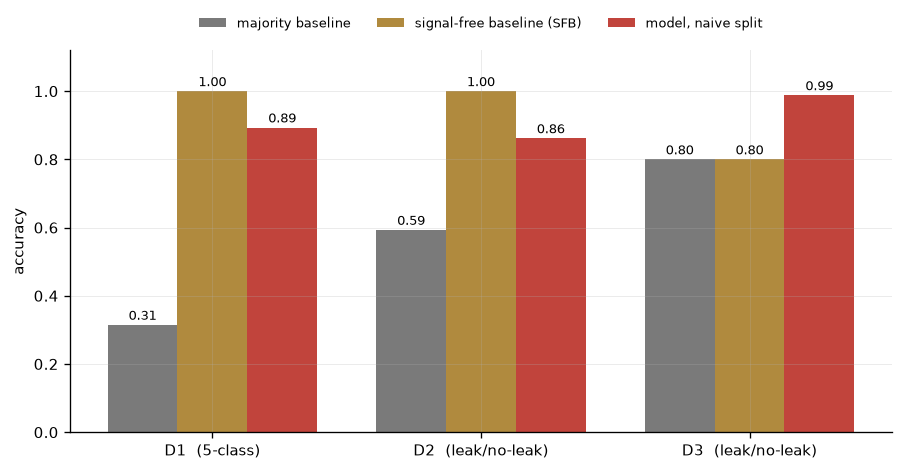

In [ ]:
# P = cfg.PALETTE
# panels = []

# # D1: naive five-class accuracy from the E4 run, if available.
# p4 = cfg.RESULTS / "E4_collapse_summary.csv"
# naive_d1 = np.nan
# if p4.exists():
#     s4 = pd.read_csv(p4)
#     r = s4[(s4.task == "T5_five_class") & (s4.protocol == "P1_naive_random")]
#     if len(r):
#         naive_d1 = float(r.acc.iloc[0])
# # Use only rows defined on the full record set, so the SFB bar and the
# # baseline bar refer to the same population.
# def full_rows(ds):
#     q = sfb_tab[(sfb_tab.dataset == ds) & sfb_tab.sfb.notna()]
#     return q[q.n == q.n.max()] if len(q) else q

# s = full_rows("D1")
# panels.append(("D1  (5-class)", float(s.baseline.iloc[0]),
#                float(s.sfb.max()), naive_d1))

# # D2: naive accuracy from the E7 run, averaged over extractors.
# p7 = cfg.RESULTS / "E7_foundation_summary.csv"
# naive_d2 = np.nan
# if p7.exists():
#     s7 = pd.read_csv(p7)
#     r = s7[s7.protocol == "P1_naive"]
#     if len(r):
#         naive_d2 = float(r.acc.max())
# s = full_rows("D2")
# if len(s):
#     panels.append(("D2  (leak/no-leak)", float(s.baseline.iloc[0]),
#                    float(s.sfb.max()), naive_d2))

# # D3: naive segment-random accuracy from the E5 run.
# p5 = cfg.RESULTS / "E5_recording_leakage_summary.csv"
# naive_d3 = np.nan
# if p5.exists():
#     s5 = pd.read_csv(p5)
#     r = s5[s5.protocol == "S1_segment_random"]
#     if len(r):
#         naive_d3 = float(r.acc.iloc[0])
# s = full_rows("D3")
# if len(s):
#     panels.append(("D3  (leak/no-leak)", float(s.baseline.iloc[0]),
#                    float(s.sfb.max()), naive_d3))

# fig, ax = plt.subplots(figsize=(7.6, 4.0))
# w, xs = 0.26, np.arange(len(panels))
# labels = [p[0] for p in panels]
# bars = [
#     ("majority baseline", [p[1] for p in panels], P["noise"]),
#     ("signal-free baseline (SFB)", [p[2] for p in panels], P["other"]),
#     ("model, naive split", [p[3] for p in panels], P["out"]),
# ]
# for i, (lab, vals, col) in enumerate(bars):
#     pos = xs + (i - 1) * w
#     ax.bar(pos, vals, width=w, color=col, label=lab)
#     for x_, v in zip(pos, vals):
#         if v == v:
#             ax.text(x_, v + 0.015, f"{v:.2f}", ha="center", fontsize=7.5)
# ax.set_xticks(xs); ax.set_xticklabels(labels)
# ax.set_ylabel("accuracy"); ax.set_ylim(0, 1.12)
# # ax.set_title("Reported accuracy against the signal-free baseline",
#             #  loc="left", fontsize=10)
# ax.legend(
#     fontsize=8,
#     loc="lower center",
#     bbox_to_anchor=(0.5, 1.02),
#     ncol=3,
#     frameon=False
# )

# fig.tight_layout()
# fig.savefig(cfg.FIGURES / "Fig0_signal_free_baseline.png", bbox_inches="tight")
# plt.show()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    context="paper",
    style="whitegrid",
    font_scale=1.0
)

P = cfg.PALETTE
panels = []


p4 = cfg.RESULTS / "E4_collapse_summary.csv"

naive_d1 = np.nan

if p4.exists():

    s4 = pd.read_csv(p4)

    r = s4[
        (s4.task == "T5_five_class") &
        (s4.protocol == "P1_naive_random")
    ]

    if len(r):
        naive_d1 = float(r.acc.iloc[0])


def full_rows(ds):

    q = sfb_tab[
        (sfb_tab.dataset == ds) &
        sfb_tab.sfb.notna()
    ]

    return (
        q[q.n == q.n.max()]
        if len(q)
        else q
    )


s = full_rows("D1")

panels.append(
    (
        "D1  (5-class)",
        float(s.baseline.iloc[0]),
        float(s.sfb.max()),
        naive_d1
    )
)


p7 = cfg.RESULTS / "E7_foundation_summary.csv"

naive_d2 = np.nan

if p7.exists():

    s7 = pd.read_csv(p7)

    r = s7[
        s7.protocol == "P1_naive"
    ]

    if len(r):
        naive_d2 = float(r.acc.max())


s = full_rows("D2")

if len(s):

    panels.append(
        (
            "D2  (leak/no-leak)",
            float(s.baseline.iloc[0]),
            float(s.sfb.max()),
            naive_d2
        )
    )


p5 = cfg.RESULTS / "E5_recording_leakage_summary.csv"

naive_d3 = np.nan

if p5.exists():

    s5 = pd.read_csv(p5)

    r = s5[
        s5.protocol == "S1_segment_random"
    ]

    if len(r):
        naive_d3 = float(r.acc.iloc[0])


s = full_rows("D3")

if len(s):

    panels.append(
        (
            "D3  (leak/no-leak)",
            float(s.baseline.iloc[0]),
            float(s.sfb.max()),
            naive_d3
        )
    )

fig, ax = plt.subplots(
    figsize=(7.6, 4.0)
)

w = 0.26
xs = np.arange(len(panels))

labels = [
    p[0]
    for p in panels
]

gray_colors = sns.color_palette(
    "Greys",
    6
)

bars = [
    (
        "majority baseline",
        [p[1] for p in panels],
        gray_colors[1]
    ),
    (
        "signal-free baseline (SFB)",
        [p[2] for p in panels],
        gray_colors[3]
    ),
    (
        "model, naive split",
        [p[3] for p in panels],
        gray_colors[5]
    ),
]

for i, (lab, vals, col) in enumerate(bars):

    pos = xs + (i - 1) * w

    bar_obj = ax.bar(
        pos,
        vals,
        width=w,
        color=col,
        label=lab,
        edgecolor="0.20",
        linewidth=0.4
    )

    # numerical labels
    for x_, v in zip(pos, vals):

        if np.isfinite(v):

            ax.text(
                x_,
                v + 0.015,
                f"{v:.2f}",
                ha="center",
                va="bottom",
                fontsize=7.5,
                color="0.15"
            )


ax.set_xticks(xs)

ax.set_xticklabels(
    labels
)

ax.set_ylabel("accuracy")
ax.set_xlabel("")

ax.set_ylim(
    0,
    1.12
)

ax.set_title("")


ax.legend(
    fontsize=8,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False
)


ax.grid(
    True,
    axis="y",
    linewidth=0.5,
    alpha=0.25
)

ax.grid(
    False,
    axis="x"
)

sns.despine(ax=ax)


fig.tight_layout()


fig.savefig(
    cfg.FIGURES / "Fig0_signal_free_baseline.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    cfg.FIGURES / "Fig0_signal_free_baseline.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()